In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
from scipy.optimize import minimize
from scipy.optimize import linprog
from scipy.optimize import LinearConstraint
from sklearn.linear_model import LinearRegression
from scipy.sparse import lil_matrix, csr_matrix
from datetime import datetime, timedelta
import torch
import torch.nn.functional as F
import math

def get_option_data(df, date_val, exdate_val):
    filtered_df = df[(df['date'] == int(date_val)) & (df['exdate'] == int(exdate_val))]
    result_df = filtered_df[['strike_price', 'cp_flag', 'best_bid', 'best_offer']]
    return result_df.to_numpy()

_spx_cache_df = pd.read_csv('spx_prices.csv', index_col=0, parse_dates=True)
_spx_cache = {
        int(pd.to_datetime(d).strftime('%Y%m%d')): float(v) 
        for d, v in _spx_cache_df['Close'].to_dict().items()
    }

def get_spx_close(date_val):
    d_int = int(date_val)
    if d_int in _spx_cache: return _spx_cache[d_int]
    return None

def process_date_exdate(df, date_val, exdate_val, S0):
    test = get_option_data(df, date_val, exdate_val)
    test_calls = test[test[:, 1] == 'C']
    test_puts = test[test[:, 1] == 'P']
    test_calls = np.delete(test_calls, 1, axis=1).astype(float)
    test_puts = np.delete(test_puts, 1, axis=1).astype(float)
    common_strikes = np.intersect1d(test_calls[:, 0], test_puts[:, 0])
    test_calls = test_calls[np.isin(test_calls[:, 0], common_strikes)]
    test_puts = test_puts[np.isin(test_puts[:, 0], common_strikes)]
    test_calls = test_calls[test_calls[:, 0].argsort()]
    test_puts = test_puts[test_puts[:, 0].argsort()]
    mid_calls = test_calls[:, 1:3].mean(axis=1)
    mid_puts = test_puts[:, 1:3].mean(axis=1)
    diff_prices = (mid_calls - mid_puts).reshape(-1, 1)
    test_avg = np.hstack((test_calls[:, [0]], diff_prices))
    X = test_avg[:, 0].reshape(-1, 1)
    y = test_avg[:, 1]
    model = LinearRegression()
    model.fit(X, y)
    B = model.coef_[0]
    A = model.intercept_
    y_pred = model.predict(X)
    lower_bound = test_calls[:, 1] - test_puts[:, 2]
    upper_bound = test_calls[:, 2] - test_puts[:, 1]
    within_bounds = (y_pred >= lower_bound) & (y_pred <= upper_bound)
    num_violations = np.sum(~within_bounds)
    if num_violations > 0:
        print("\nViolations found at these strikes:")
        violations_df = pd.DataFrame({
            'Strike': X.flatten()[~within_bounds],
            'Lower Bound': lower_bound[~within_bounds],
            'Predicted': y_pred[~within_bounds],
            'Upper Bound': upper_bound[~within_bounds]
        })
        display(violations_df)
        raise ValueError
    D = -B
    F = A/D
    strike_scale = S0 / F
    price_scale = S0 / (D * F)
    test_calls[:, 0] = test_calls[:, 0] * strike_scale
    test_calls[:, 1:3] = test_calls[:, 1:3] * price_scale
    test_puts[:, 0] = test_puts[:, 0] * strike_scale
    test_puts[:, 1:3] = test_puts[:, 1:3] * price_scale
    K = test_calls[:, 0]
    C_h = np.minimum(test_calls[:, 2], test_puts[:, 2] + S0 - K)
    C_l = np.maximum(test_calls[:, 1], test_puts[:, 1] + S0 - K)
    return K, C_l, C_h


# Previous implementation with scipy and analytic center

# def find_inital_point(S0, K_Union, bid_ask_compiled, Kbar):
#     M = len(bid_ask_compiled)
#     N = len(K_Union)
#     L = 0.0
#     dK = np.diff(K_Union)
#     total_vars = M * N

#     market_counts = [market_data.shape[0] for market_data in bid_ask_compiled]
#     expected_rows = M * (N + 3) + 2 * sum(market_counts) + (M - 1) * N
#     # Use a large LIL matrix for construction
#     A_ub = lil_matrix((expected_rows, total_vars))
#     print((expected_rows, total_vars))
#     b_ub = []
#     row = 0

#     for m in range(M):
#         offset = m * N
        
#         # 1. Convexity: -C_i/dK_i + C_{i+1}(1/dK_i + 1/dK_{i+1}) - C_{i+2}/dK_{i+1} <= 0
#         for i in range(N - 2):
#             A_ub[row, offset + i] = -1.0 / dK[i]
#             A_ub[row, offset + i + 1] = 1.0 / dK[i] + 1.0 / dK[i + 1]
#             A_ub[row, offset + i + 2] = -1.0 / dK[i + 1]
#             b_ub.append(0.0)
#             row += 1
        
#         # 3. Boundary Constraints
#         # C[0] >= S0 - K_Union[0] => -C[0] <= K_Union[0] - S0
#         A_ub[row, offset] = -1.0
#         b_ub.append(K_Union[0] - S0)
#         row += 1
        
#         # Slope convexity at L
#         A_ub[row, offset] = 1.0 / (K_Union[0] - L) + 1.0 / dK[0]
#         A_ub[row, offset + 1] = -1.0 / dK[0]
#         b_ub.append((S0 - L) / (K_Union[0] - L))
#         row += 1
        
#         # Slope convexity at Kbar
#         A_ub[row, offset + N - 2] = -1.0 / dK[-1]
#         A_ub[row, offset + N - 1] = 1.0 / (Kbar - K_Union[-1]) + 1.0 / dK[-1]
#         b_ub.append(0.0)
#         row += 1

#         A_ub[row, offset + N - 1] = -1.0
#         b_ub.append(0.0)
#         row += 1
        
#         # C[0] <= S0 - L
#         A_ub[row, offset] = 1.0
#         b_ub.append(S0 - L)
#         row += 1
        
#         # 3. Market Bounds
#         market_data = bid_ask_compiled[m]
#         m_strikes = market_data[:, 0]
#         m_lower = market_data[:, 1]
#         m_upper = market_data[:, 2]
#         indices = np.searchsorted(K_Union, m_strikes)
        
#         for i, idx in enumerate(indices):
#             # C <= upper
#             A_ub[row, offset + idx] = 1.0
#             b_ub.append(m_upper[i])
#             row += 1
#             # -C <= -lower
#             A_ub[row, offset + idx] = -1.0
#             b_ub.append(-m_lower[i])
#             row += 1

#     # 4. Temporal monotonicity: C_{m, n} - C_{m+1, n} <= 0
#     for m in range(M - 1):
#         for n in range(N):
#             A_ub[row, m * N + n] = 1.0
#             A_ub[row, (m + 1) * N + n] = -1.0
#             b_ub.append(0.0)
#             row += 1

#     if row != expected_rows or len(b_ub) != row:
#         raise RuntimeError(
#             f"Constraint row mismatch: appended {row}, expected {expected_rows}"
#         )

#     A_ub = A_ub[:row, :].tocsr()
#     b_ub = np.asarray(b_ub, dtype=float)

#     def objective(x):
#         slack = b_ub - A_ub @ x
#         return -np.prod(slack)

#     def jacobian(x):
#         slack = b_ub - A_ub @ x

#         # if np.any(slack <= 0):
#         #     # This point is outside the domain of the product barrier.
#         #     return np.zeros_like(x)

#         product_slack = np.prod(slack)
#         return product_slack * (A_ub.T @ (1.0 / slack))

#     def objective_log(x):
#         slack = b_ub - A_ub @ x
#         if np.any(slack <= 0):
#             return np.inf # Prevent log of negative numbers
#         return -np.sum(np.log(slack))

#     def jacobian_log(x):
#         slack = b_ub - A_ub @ x
#         # If constraints are violated, push gradient back into feasible region
#         if np.any(slack <= 0):
#             # A simple penalty gradient to push it back
#             return -A_ub.T @ np.where(slack <= 0, -1e6, 1.0 / slack)
#         return A_ub.T @ (1.0 / slack)

#     res_lp = linprog(
#         np.zeros(total_vars),
#         A_ub=A_ub,
#         b_ub=b_ub,
#         bounds=(0, None),
#         method="highs-ipm"
#     )

#     if not res_lp.success:
#         raise ValueError(f"Initial feasibility failed: {res_lp.message}")
    
#     x0 = res_lp.x
#     cons = LinearConstraint(A_ub, lb=-np.inf, ub=b_ub)

#     res_opt = minimize(
#             objective, 
#             x0, 
#             method='trust-constr', 
#             constraints=cons
#     )
    
#     if not res_opt.success:
#         print("Optimization warning:", res_opt.message)
#         return x0.reshape((M, N))

#     slack = b_ub - A_ub @ res_opt.x
#     tol = 1e-8

#     print("Minimum slack:", np.min(slack))
#     print("Maximum violation:", max(0.0, -np.min(slack)))
#     print("Constraints satisfied:", np.all(slack >= -tol))

#     plt.plot(K_Union, res_opt.x.reshape((M, N)).T)    
#     return res_opt.x.reshape((M, N))

def load_theta(S, C, K, L, Kbar, prev_sigs=None, prev_nus=None):

    prev_c_vals1, prev_c_vals2 = None, None
    if prev_sigs is not None: prev_c_vals1, prev_c_vals2 = load_c_values(S, prev_sigs, prev_nus)

    def A_t(sigma,A,B,K):
        return 0.5 * ((A-sigma*B)*np.exp(-K/sigma) + (A+sigma*B)*np.exp(K/sigma))

    def B_t(sigma,A,B,K):
        return (1/(2 * sigma)) * (-(A-sigma*B)*np.exp(-K/sigma) + (A+sigma*B)*np.exp(K/sigma))

    def bisect(f, low, high, tol=1e-8):
        if f(low) < 0: return low
        elif f(high) > 0: return high
        while (high - low) > tol:
            mid = (low + high) / 2
            if mid == low or mid == high: return mid
            if f(mid) < 0:
                high = mid
            else:
                low = mid
        return (low + high) / 2

    def SigmaHat(A,B,K1,K2,V):
        my_eps = 1.0e-8
        def SigmaHat_obj(sigma): return A_t(sigma,A,B,K1) + B_t(sigma,A,B,K1)*K2 - V
        low = my_eps
        high = 1.0
        while (SigmaHat_obj(high) > 0): high = 2.0*high
        result = bisect(SigmaHat_obj, low, high)
        return result

    def SigmaTilde(sigma,A,B,K1,K2,V):
        my_eps = 1.0e-8
        At, Bt = A_t(sigma,A,B,K1), B_t(sigma,A,B,K1)
        def SigmaTilde_obj(sigma_t): return A_t(sigma_t,At,Bt,K2) - V
        low = my_eps
        high = 1.0
        while (SigmaTilde_obj(high) > 0): high = 2.0*high
        result = bisect(SigmaTilde_obj, low, high)
        return result

    def CalibrateTwoSigmas(A,B,K1,K2,V,B1):
        def TwoSigma_obj(sigma):
            sigma_t = SigmaTilde(sigma,A,B,K1,K2,V)
            At, Bt = A_t(sigma,A,B,K1), B_t(sigma,A,B,K1)
            return B1 - B_t(sigma_t,At,Bt,K2)
        low = SigmaHat(A,B,K1,K2,V)
        high = low + 1
        while (TwoSigma_obj(high) > 0): high = 2.0*high
        result = bisect(TwoSigma_obj, low, high)
        return result, SigmaTilde(result,A,B,K1,K2,V)

    def CalibrateThreeSigmas(A,B,K1,K2,K3,W,V,B1):
        sigma1 = SigmaHat(A,B,K1,K2,W)
        At, Bt = A_t(sigma1,A,B,K1), B_t(sigma1,A,B,K1)
        sigma2, sigma3 = CalibrateTwoSigmas(At,Bt,K2,K3,V,B1)
        return sigma1, sigma2, sigma3

    def Intersection_obj(K, A, B, x):
        return A + B * (x-K) - V_K(S, prev_sigs, prev_nus, prev_c_vals1, prev_c_vals2, x)

    i0 = np.searchsorted(K, S)
    
    Lt1 = C[i0-1] + (S-K[i0-1])*(C[i0-1]-C[i0-2])/(K[i0-1]-K[i0-2])
    Lt2 = C[i0] + (S-K[i0])*(C[i0+1]-C[i0])/(K[i0+1]-K[i0])
    Lt = max([Lt1,Lt2])
    
    Ut = C[i0-1]*(K[i0]-S)/(K[i0]-K[i0-1]) + C[i0]*(S-K[i0-1])/(K[i0]-K[i0-1])
    
    delta = 0.5
    Vtemp = delta*Lt + (1-delta)*Ut
    
    K1 = np.concatenate(([L], K[:i0], [S]))
    V1 = np.concatenate(([0], C[:i0] - S + K[:i0], [Vtemp]))
    
    K2 = np.concatenate(([0], Kbar - K[i0:][::-1], [Kbar - S]))
    V2 = np.concatenate(([0], C[i0:][::-1], [Vtemp]))

    def CalibrationAlgorithm(K0, K1, A, V, B, B1):
        nu = []
        sigmas = []
        flag = False
        if prev_sigs is not None:
            cross1 = bisect(lambda x: Intersection_obj(K0, A, B, x), K0+1e-8, K1-1e-8)
            cross2 = bisect(lambda x: -Intersection_obj(K1, V, B1, x), K0+1e-8, K1-1e-8)
            flag = cross1 < cross2
        if flag:
            w1 = min((K1-K0)/3, cross1-K0)
            w2 = max((K1-K0)*2/3, cross2-K0)
            W = V + B1 * (w2+K0-K1)
            sigma1, sigma2, sigma3 = CalibrateThreeSigmas(A, B, w1, w2-w1, K1-K0-w2, W, V, B1)
            nu.append(K0)
            nu.append(K0+w1)
            nu.append(K0+w2)
            sigmas.append(sigma1)
            sigmas.append(sigma2)
            sigmas.append(sigma3)
        else:
            w = (V + B*K0 - A - B1*K1)/(B-B1)
            sigma1, sigma2 = CalibrateTwoSigmas(A, B, w-K0, K1-w, V, B1)
            nu.append(K0)
            nu.append(w)
            sigmas.append(sigma1)
            sigmas.append(sigma2)
        return nu, sigmas

    def Interpolate(K,V):
        N = len(K)
        nu = []
        sigmas = []
        delta = 0.5
        B = delta*(V[1]-V[0])/(K[1]-K[0])
        print("Slope diffs:", np.min(np.diff(np.diff(V)/np.diff(K))))
        
        for i in range(N-2):
            K0 = K[i]
            K1 = K[i+1]
            K2 = K[i+2]
            A = V[i]
            V1 = V[i+1]
            V2 = V[i+2]
            h_left = K1 - K0
            h_right = K2 - K1
            s_left = (V1 - A) / h_left
            s_right = (V2 - V1) / h_right
            # Weighted average of slopes to determine B1
            B1 = (h_right * s_left + h_left * s_right) / (h_left + h_right)
            nus_new, sigmas_new = CalibrationAlgorithm(K0, K1, A, V1, B, B1)
            nu.extend(nus_new)
            sigmas.extend(sigmas_new)
            B=B1
        return nu, sigmas, B

    nu1, sigmas1, B1_last = Interpolate(K1,V1)
    nu2, sigmas2, B2_last = Interpolate(K2,V2)

    delta1 = 0.5
    rho = delta1 + delta1*(V2[-2]-V2[-1])/(K2[-1]-K2[-2]) + (1.0-delta1)*(V1[-1]-V1[-2])/(K1[-1]-K1[-2])

    K1t = K1[-2]
    K2t = K1[-1]
    A = V1[-2]
    V2t = V1[-1]
    B = B1_last
    B1 = rho
    nus_new, sigmas_new = CalibrationAlgorithm(K1t, K2t, A, V2t, B, B1)
    nu1.extend(nus_new)
    sigmas1.extend(sigmas_new)

    K1t = K2[-2]
    K2t = K2[-1]
    A = V2[-2]
    V2t = V2[-1]
    B = B2_last
    B1 = 1 - rho
    nus_new, sigmas_new = CalibrationAlgorithm(K1t, K2t, A, V2t, B, B1)
    nu2.extend(nus_new)
    sigmas2.extend(sigmas_new)

    sigs = np.concatenate([sigmas1, sigmas2[::-1]])
    nus = np.concatenate([nu1, [S], Kbar - np.array(nu2[::-1])])
    return sigs, nus

def load_c_values(S0, sigs, nus):
    # Ensure inputs are evaluated as Pynp operations
    R1 = np.searchsorted(nus, S0)
    nus1, sigs1 = nus[:R1+1], sigs[:R1]
    nus2, sigs2 = nus[R1:], sigs[R1:]

    c_vals1 = []
    dist0 = nus1[1] - nus1[0]
    # Use np.stack to combine scalars into a 1D tensor
    c_vals1.append(np.stack([-np.exp(-dist0/sigs1[0]), np.exp(dist0/sigs1[0])]))
    
    for i in range(len(sigs1) - 1):
        A = c_vals1[-1][0] + c_vals1[-1][1]
        B = (1/sigs1[i]) * (-c_vals1[-1][0] + c_vals1[-1][1])
        
        dist = nus1[i+2] - nus1[i+1]
        
        c_vals1.append(np.stack([
            0.5 * (A - sigs1[i+1]*B) * np.exp(-dist/sigs1[i+1]), 
            0.5 * (A + sigs1[i+1]*B) * np.exp(dist/sigs1[i+1])
        ]))

    # 2. Right side propagation
    c_vals2 = [None] * len(sigs2)
    dist_end = nus2[-1] - nus2[-2]
    c_vals2[-1] = np.stack([np.exp(dist_end/sigs2[-1]), -np.exp(-dist_end/sigs2[-1])])
    
    for i in range(len(sigs2) - 1, 0, -1):
        A = c_vals2[i][0] + c_vals2[i][1]
        B = (1/sigs2[i]) * (-c_vals2[i][0] + c_vals2[i][1])
        
        dist = nus2[i] - nus2[i-1]
        
        c_vals2[i-1] = np.stack([
            0.5 * (A - sigs2[i-1]*B) * np.exp(dist/sigs2[i-1]), 
            0.5 * (A + sigs2[i-1]*B) * np.exp(-dist/sigs2[i-1])
        ])
        
    # Stack the lists into 2D tensors
    c_vals1_tensor = np.stack(c_vals1)
    c_vals2_tensor = np.stack(c_vals2)

    # 3. Jump condition matching
    v1 = c_vals1_tensor[-1, 0] + c_vals1_tensor[-1, 1]
    Dk_v1 = (1/sigs1[-1]) * (-c_vals1_tensor[-1, 0] + c_vals1_tensor[-1, 1])
    
    v2 = c_vals2_tensor[0, 0] + c_vals2_tensor[0, 1]
    Dk_v2 = (1/sigs2[0]) * (-c_vals2_tensor[0, 0] + c_vals2_tensor[0, 1])
    
    denom = (Dk_v1 * v2 - v1 * Dk_v2)
    lam1, lam2 = v2 / denom, v1 / denom

    c_v1 = c_vals1_tensor * lam1
    c_v2 = c_vals2_tensor * lam2

    return c_v1, c_v2

def V_K(S0, sigs, nus, c_v1, c_v2, K):
    R1 = np.searchsorted(nus, S0)
    nus1, sigs1 = nus[:R1+1], sigs[:R1]
    nus2, sigs2 = nus[R1:], sigs[R1:]

    if K < nus[0]:
        return 0
    elif K > nus[-1]:
        return 0
    elif K < S0:
        idx = np.clip(np.searchsorted(nus1, K), 1, len(sigs1))
        dist = nus1[idx] - K
        sigma = sigs1[idx - 1]
        result = c_v1[idx - 1, 0] * np.exp(dist/sigma) + c_v1[idx - 1, 1] * np.exp(-dist/sigma)
    else:
        idx = np.clip(np.searchsorted(nus2, K, side='right'), 1, len(sigs2))
        dist = K - nus2[idx - 1]
        sigma = sigs2[idx - 1]
        result = c_v2[idx - 1, 0] * np.exp(-dist/sigma) + c_v2[idx - 1, 1] * np.exp(dist/sigma)
    
    return result

# def validate_and_check_market(S0, sigs, nus, bid_ask_arr, plot=False):
#     R1 = np.searchsorted(nus, S0)
#     nus1, sigs1 = nus[:R1+1], sigs[:R1]
#     nus2, sigs2 = nus[R1:], sigs[R1:]
#     R2 = len(sigs2)
    
#     c_v1, c_v2 = load_c_values(S0, sigs, nus)

#     mask_left = K_vec <= S0
#     mask_right = ~mask_left
#     results = np.zeros_like(K_vec)
#     if np.any(mask_left):
#         K_left = K_vec[mask_left]
#         indices = np.searchsorted(nus1, K_left, side='left') - 1
#         indices = np.clip(indices, 0, R1 - 1)
#         dist = nus1[indices + 1] - K_left
#         results[mask_left] = (c_v1[indices, 0] * np.exp(dist/sigs1[indices]) + c_v1[indices, 1] * np.exp(-dist/sigs1[indices])) + S0 - K_left

#     if np.any(mask_right):
#         K_right = K_vec[mask_right]
#         indices = np.searchsorted(nus2, K_right, side='left') - 1
#         indices = np.clip(indices, 0, R2 - 1)
#         dist = K_right - nus2[indices]
#         results[mask_right] = (c_v2[indices, 0] * np.exp(-dist/sigs2[indices]) + c_v2[indices, 1] * np.exp(dist/sigs2[indices]))


def plot_V_K(S0, sigs, nus, ax=None, label=None):
    c_v1, c_v2 = load_c_values(S0, sigs, nus)
    K_vals = np.linspace(S0 - 200, S0 + 200, 1000)
    V_vals = np.array([V_K(S0, sigs, nus, c_v1, c_v2, k)+ max(S0-k,0) for k in K_vals])
    
    ax.plot(K_vals, V_vals, label=str(label))
    ax.set_xlabel('K')
    ax.set_ylabel('V(K)')
    ax.set_title('Plot of $V(K)$ against $K$')
    ax.legend()
    ax.grid(True)

    if ax is None: plt.show()


In [10]:
import cvxpy as cp

# Chebyshev center with cvxpy implementation for finding an initial feasible point

def find_inital_point(S0, K_Union, bid_ask_compiled, Kbar):
    M = len(bid_ask_compiled)
    N = len(K_Union)
    L = 0.0
    dK = np.diff(K_Union)
    total_vars = M * N

    market_counts = [market_data.shape[0] for market_data in bid_ask_compiled]
    expected_rows = M * (N + 2) + 2 * sum(market_counts) + (M - 1) * N
    A_ub = lil_matrix((expected_rows, total_vars))
    b_ub = []
    row = 0

    for m in range(M):
        offset = m * N

        for i in range(N - 2):
            A_ub[row, offset + i] = -1.0 / dK[i]
            A_ub[row, offset + i + 1] = 1.0 / dK[i] + 1.0 / dK[i + 1]
            A_ub[row, offset + i + 2] = -1.0 / dK[i + 1]
            b_ub.append(0.0)
            row += 1

        A_ub[row, offset] = -1.0
        b_ub.append(K_Union[0] - S0)
        row += 1

        A_ub[row, offset] = 1.0 / (K_Union[0] - L) + 1.0 / dK[0]
        A_ub[row, offset + 1] = -1.0 / dK[0]
        b_ub.append((S0 - L) / (K_Union[0] - L))
        row += 1

        A_ub[row, offset + N - 2] = -1.0 / dK[-1]
        A_ub[row, offset + N - 1] = 1.0 / (Kbar - K_Union[-1]) + 1.0 / dK[-1]
        b_ub.append(0.0)
        row += 1

        A_ub[row, offset] = 1.0
        b_ub.append(S0 - L)
        row += 1

        market_data = bid_ask_compiled[m]
        m_strikes = market_data[:, 0]
        m_lower = market_data[:, 1]
        m_upper = market_data[:, 2]
        indices = np.searchsorted(K_Union, m_strikes)

        for i, idx in enumerate(indices):
            A_ub[row, offset + idx] = 1.0
            b_ub.append(m_upper[i])
            row += 1

            A_ub[row, offset + idx] = -1.0
            b_ub.append(-m_lower[i])
            row += 1

    for m in range(M - 1):
        for n in range(N):
            A_ub[row, m * N + n] = 1.0
            A_ub[row, (m + 1) * N + n] = -1.0
            b_ub.append(0.0)
            row += 1

    if row != expected_rows or len(b_ub) != row:
        raise RuntimeError(
            f"Constraint row mismatch: appended {row}, expected {expected_rows}"
        )

    A_ub = A_ub[:row, :].tocsr()
    b_ub = np.asarray(b_ub, dtype=float)

    # Normalize every inequality without changing its feasible half-space.
    row_norms = np.sqrt(np.asarray(A_ub.multiply(A_ub).sum(axis=1)).ravel())
    if np.any(row_norms <= 0.0):
        raise ValueError("Constraint matrix contains a zero-norm row")
    A_ub = A_ub.multiply(1.0 / row_norms[:, None]).tocsr()
    b_ub = b_ub / row_norms

    # With normalized rows, the common slack radius is the Euclidean distance
    # to each constraint boundary, so this is the Chebyshev-center LP.
    prices = cp.Variable(total_vars, nonneg=True)
    radius = cp.Variable(nonneg=True)
    constraints = [
        cp.Constant(A_ub) @ prices + radius <= b_ub
    ]

    problem = cp.Problem(cp.Maximize(radius), constraints)
    problem.solve(solver=cp.CLARABEL)

    if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise ValueError(f"Chebyshev-center solve failed: {problem.status}")

    initial_point = np.asarray(prices.value).reshape((M, N))
    margin = float(radius.value)
    slack = b_ub - A_ub @ initial_point.ravel()
    max_violation = max(0.0, -float(np.min(slack)))

    print("Chebyshev radius:", margin)
    print("Minimum normalized constraint slack:", float(np.min(slack)))
    print("Maximum constraint violation:", max_violation)

    if max_violation > 1e-7 or np.min(initial_point) < -1e-7:
        raise ValueError("CVXPY returned a point outside the normalized constraints")

    plt.plot(K_Union, initial_point.T)
    return initial_point

In [11]:
import random

def plot_sigs(S0, sigs, nus, ax=None, label=None):
    random_color = (random.random(), random.random(), random.random())
    if ax is None: fig, ax = plt.subplots(figsize=(20, 8))
    log_sigs = np.log10(sigs)
    first = True
    for i in range(len(sigs)):
        if nus[i] > S0 - 100 and nus[i] < S0 + 100:
            if first:
                ax.plot([np.log(nus[i]/S0), np.log(nus[i+1]/S0)], [log_sigs[i], log_sigs[i]], lw=0.5, color=random_color, label=str(label))
                first = False
            else: ax.plot([np.log(nus[i]/S0), np.log(nus[i+1]/S0)], [log_sigs[i], log_sigs[i]], lw=0.5, color=random_color)
            if (i != len(sigs)-1):
                ax.plot([np.log(nus[i+1]/S0), np.log(nus[i+1]/S0)], [log_sigs[i], log_sigs[i+1]], lw=0.5, color=random_color)
    ax.set_xlabel('log(K/S0)')
    ax.set_ylabel('log10(Sigma)')
    ax.set_title('Plot of log10(sigmas)')
    ax.legend()
    ax.grid(True)
    if ax is None: plt.show()

def test_date_index(INDEX, dataframe):
    df = dataframe.copy()
    df['dt_date'] = pd.to_datetime(df['date'], format='%Y%m%d')
    df['dt_exdate'] = pd.to_datetime(df['exdate'], format='%Y%m%d')
    date_counts = df.groupby('date')['exdate'].nunique()
    valid_dates = sorted(date_counts[date_counts > 0].index.tolist())
    if INDEX >= len(valid_dates):
        print(f"Index {INDEX} out of range for {len(valid_dates)} valid dates.")
        return
    target_date = valid_dates[INDEX]
    exdates = sorted(df[df['date'] == target_date]['exdate'].unique())
    exdates = exdates
    K_Union = np.array([])
    bid_ask_compiled = []
    S0 = get_spx_close(target_date)
    print("Num maturities:", len(exdates))
    for exdate in exdates:
        K_curr, C_l, C_h = process_date_exdate(dataframe, target_date, exdate, S0)
        bid_ask_compiled.append(np.column_stack([K_curr, C_l, C_h]))
        K_Union = np.unique(np.concatenate((K_Union, K_curr)))
    

    K_Union = np.sort(K_Union)
    print("Num strikes:", len(K_Union))
    Kbar = K_Union[-1] + 20
    
    initial_points = find_inital_point(S0, K_Union, bid_ask_compiled, Kbar)

    prev_sigs, prev_nus = None, None

    fig, axs = plt.subplots(2, 1, figsize=(20, 12))
    target_date_dt = pd.to_datetime(target_date, format='%Y%m%d')
    for i, exdate in enumerate(exdates):
        exdate_dt = pd.to_datetime(exdate, format='%Y%m%d')
        t_to_expiry = len(pd.bdate_range(target_date_dt, exdate_dt)) - 1
        K_curr, C_l, C_h = process_date_exdate(dataframe, target_date, exdate, S0)
        sigs, nus = load_theta(S0, initial_points[i], K_Union, 0, Kbar,prev_sigs=prev_sigs, prev_nus=prev_nus)

        plot_V_K(S0, sigs, nus, ax=axs[0], label=t_to_expiry)
        plot_sigs(S0, sigs, nus, ax=axs[1], label=t_to_expiry)
        prev_sigs = sigs
        prev_nus = nus
    plt.title(f"V(K) Surface Evolution for {target_date}")
    plt.legend()
    plt.show()
        


Num maturities: 11
Num strikes: 763
Chebyshev radius: 3.5110338555872497e-07
Minimum normalized constraint slack: 3.511235502946787e-07
Maximum constraint violation: 0.0
Slope diffs: 2.3215334681534892e-08
Slope diffs: 5.15605199116598e-07
Slope diffs: 1.4749065176064907e-07
Slope diffs: 1.168364428469545e-06
Slope diffs: 1.4391378217759925e-06
Slope diffs: 2.3372335863501608e-06
Slope diffs: 2.106609090927363e-06
Slope diffs: 4.5847896212157936e-06
Slope diffs: 1.8900001377597145e-06
Slope diffs: 4.805248488463847e-06
Slope diffs: 1.3009431655360947e-05
Slope diffs: 1.5500958238501037e-05
Slope diffs: 3.29402059191993e-05
Slope diffs: 1.8810754425759377e-05
Slope diffs: 5.381487967638882e-05
Slope diffs: 1.9259189246045795e-05
Slope diffs: 7.04938962433851e-05
Slope diffs: 2.1547652283184133e-05
Slope diffs: 2.7765456808896173e-05
Slope diffs: 1.5263765158877996e-05
Slope diffs: 0.0001054988855186895
Slope diffs: 3.117709302631242e-05


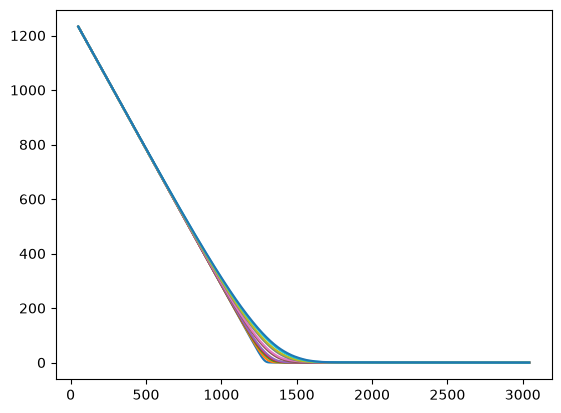

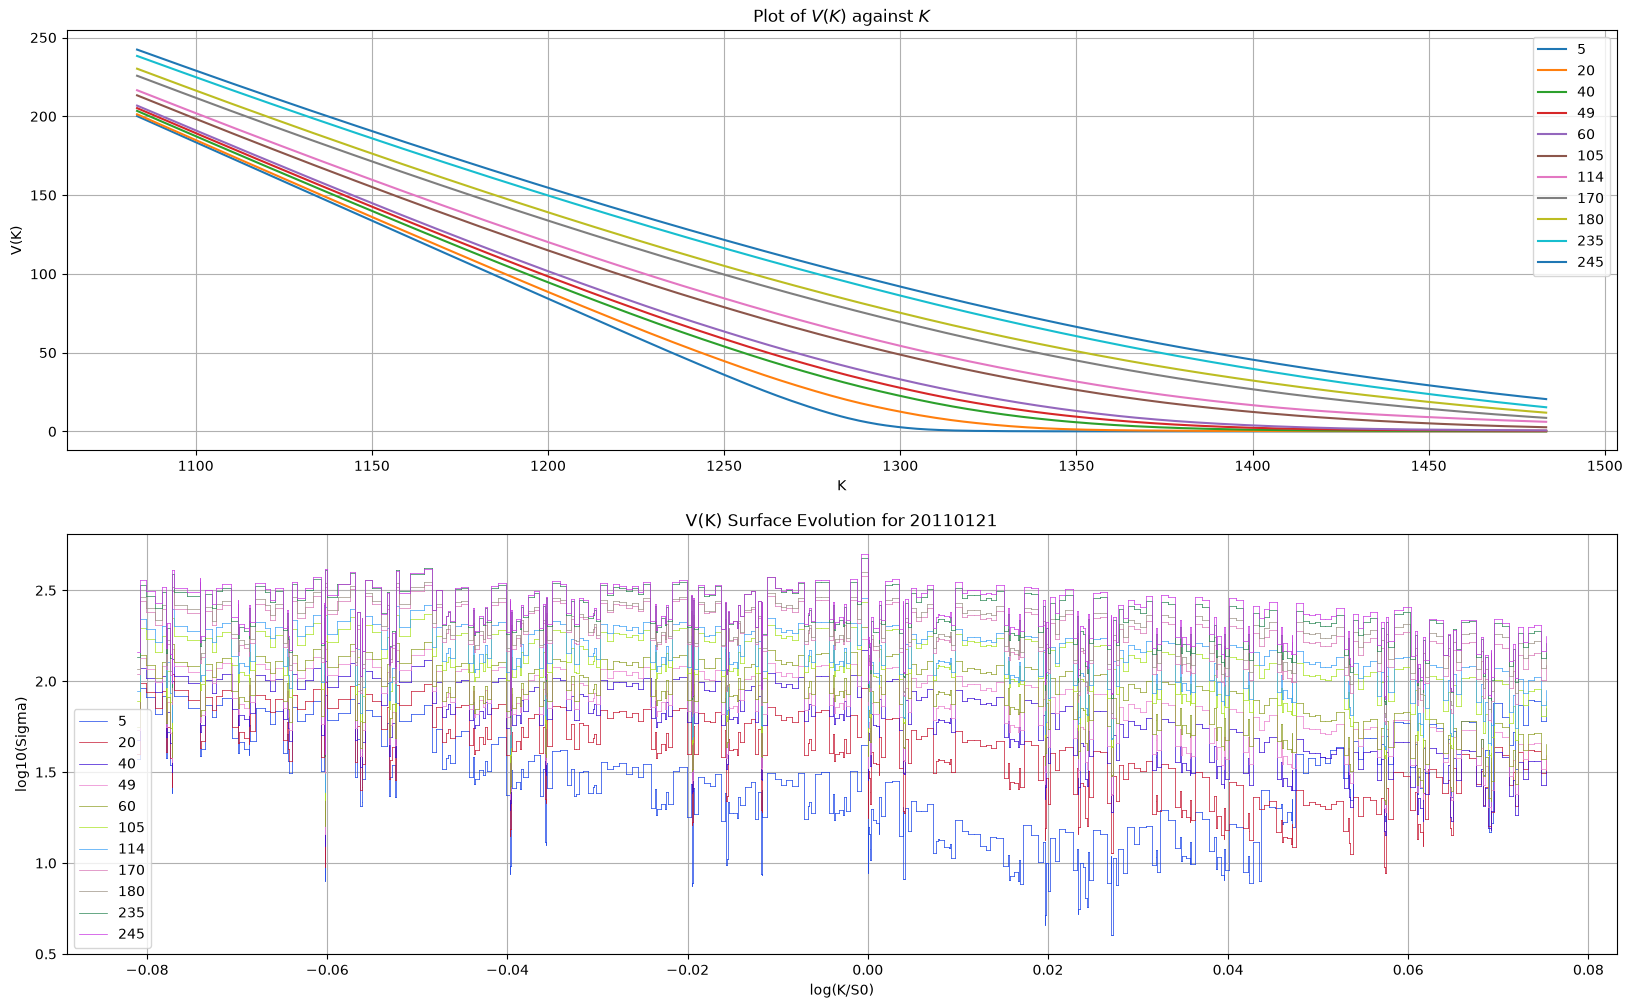

In [12]:
import warnings
warnings.filterwarnings('ignore')

dataframe = pd.read_csv("datasets/SPX_opt_2011_2012.csv")

test_date_index(13, dataframe)